---
## Trabalho Prático III - Individual
## Data de entrega: 26/09/2024
---


# <font color='yellow'>K-Means</font>

Um dos algoritmos mais conhecido e antigo (proposto em 1967 por James MacQueen), esse algoritmo baseado em centróides, tem como objetivo, encontrar os agrupamentos nos dados nos quais a variância dentro de cada cluster seja mínima.

<font color='yellow'>Parâmetro de entrada - n_clusters</font> - número de clusters que queremos obter/acreditamos que existe.

<font color='yellow'>**Funcionamento**</font>

O algoritmo tem como base inserir _K_ centróides aleatórios (sendo _K_ o número de clusters) e, a partir desses pontos, ajustá-los com base nos dados, a fim de encontrar o centro dos clusters.

1.  O algoritmo escolhe _k_ pontos aleatórios, sendo _k_ o número de clusters que foram definidos como parâmetro;
2.  Computada a distância de cada ponto ao centróide mais próximo. Dessa forma, criamos a divisão dos dados entre os clusters, sendo cada cluster o conjunto de dados mais próximos aos centróides;
3.  Com esses grupos definidos, os novos valores dos centróides (pontos centrais dos clusters) serão as médias dos dados de cada cluster;
4.  Com os novos valores dos centróides, realizamos as mesmas etapas novamente: identificamos os pontos mais próximos aos centróides e criamos novos clusters, e a partir desses clusters, calculamos o valor médio para gerar novos valores para os centróides.


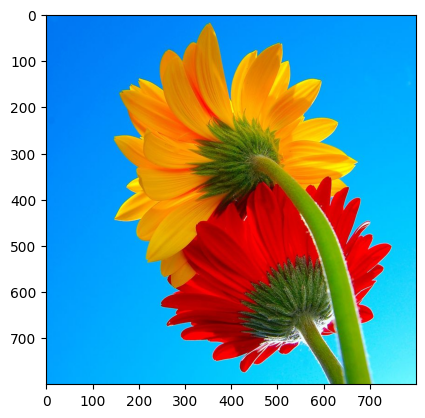

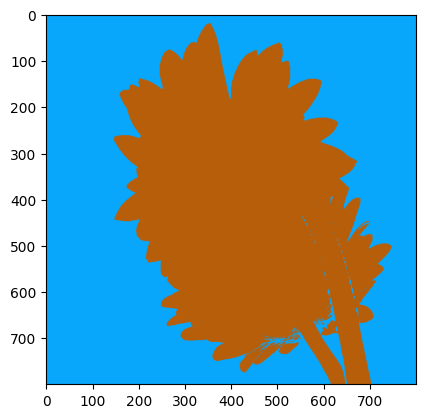

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# A função IMREAD carrega a imagem em formato BGR
image = cv2.imread('./flor.jpeg')
k = 2  # número de clusters (K)

# Converte para RGB
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.show()

# Remodelar a imagem para uma matriz 2D de pixels, ou seja, 3 colunas de cores (RGB)
# Cada linha representa um pixel e cada coluna a sua intensidade de cada canal/cores
# -1: ajuste automaticamente cada linha da matriz ao número total de pixels na imagem
pixel_values = image.reshape((-1, 3))

# Converte para float
pixel_values = np.float32(pixel_values)

# Critério de parada do algoritmo KMeans
# TERM_CRITERIA_EPS: itera até que a mudança na posição dos centróides entre duas iterações consecutivas seja menor ou igual a EPS (épsilon)
# TERM_CRITERIA_MAX_ITER - 100
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)

# https://docs.opencv.org/3.4/d1/d5c/tutorial_py_kmeans_opencv.html
compactness, labels, (centers) = cv2.kmeans(
    pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# Converte os centros do cluster de volta para o tipo de dados uint8, pois o OpenCV espera este formato para exibição de imagens
centers = np.uint8(centers)

labels = labels.flatten()

# Cria uma nova imagem  onde o valor de cada pixel é substituído pelo valor central do cluster correspondente da
# matriz de centros com base no rótulo de cluster atribuído na matriz de rótulos
segmented_image = centers[labels]

# Remodelar de volta à dimensão original da imagem
segmented_image = segmented_image.reshape(image.shape)

plt.imshow(segmented_image)
plt.show()


Aplicação de uma máscara em uma imagem segmentada com base nos rótulos dos clusters obtidos pelo algoritmo K-means.

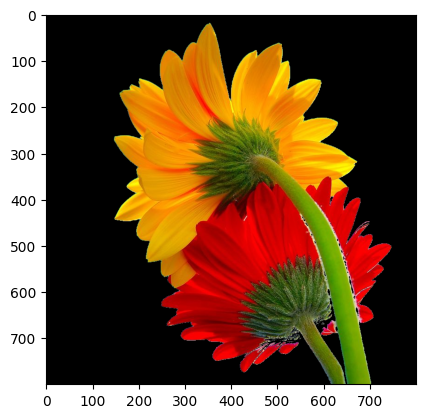

In [2]:
masked_image = np.copy(image)

masked_image = masked_image.reshape((-1, 3))
# Desabilitar um dos clusteres (i.e a cor)
cluster = 1
masked_image[labels == cluster] = [0, 0, 0]

masked_image = masked_image.reshape(image.shape)
plt.imshow(masked_image)
plt.show()


Aplique o algoritmo baseado em densidade, DBScan (Density-Based Spatial Clustering of Applications with Noise), para realização de segmentação de imagens.

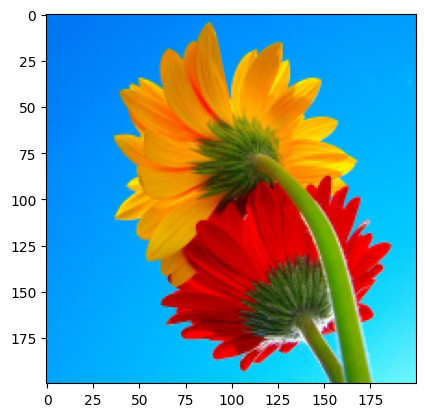

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..252.0].


Number of clusters: 16


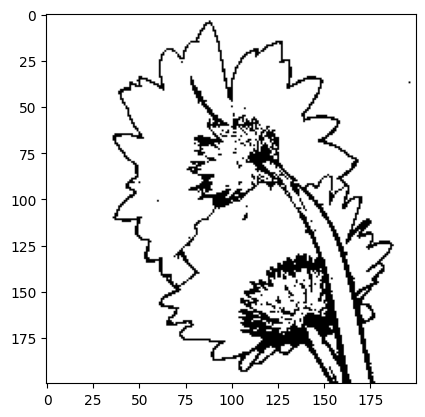

In [3]:
from sklearn.cluster import DBSCAN

image = cv2.imread('./flor.jpeg')

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image = cv2.resize(image, (200, 200), interpolation=cv2.INTER_AREA)
plt.imshow(image)
plt.show()

pixel_values = image.reshape((-1, 3))
pixel_values = np.float32(pixel_values)

db = DBSCAN(eps=5, min_samples=10).fit(pixel_values)
labels = db.labels_
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

print(f"Number of clusters: {n_clusters}")

unique_labels = np.unique(labels)
centers = []
for label in unique_labels:
    if label == -1:
        continue
    cluster_points = pixel_values[labels == label]
    cluster_center = np.mean(cluster_points, axis=0)
    centers.append(cluster_center)

centers = np.uint8(centers)
segmented_image = np.zeros_like(pixel_values)
for label in unique_labels:
    if label == -1:
        segmented_image[labels == label] = [0, 0, 0]
    else:
        segmented_image[labels == label] = centers[label]

segmented_image = segmented_image.reshape(image.shape)
plt.imshow(segmented_image)
plt.show()
